# exploracion María Paula Rangel Triana
pruebas de mis items (2, 4, 6, 8 y 10)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../datos/AB_NYC_2019.csv")

## item 2

In [2]:
df.isnull().sum()

id                                    0
name                                 16
host_id                               0
host_name                            21
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
last_review                       10052
reviews_per_month                 10052
calculated_host_listings_count        0
availability_365                      0
dtype: int64

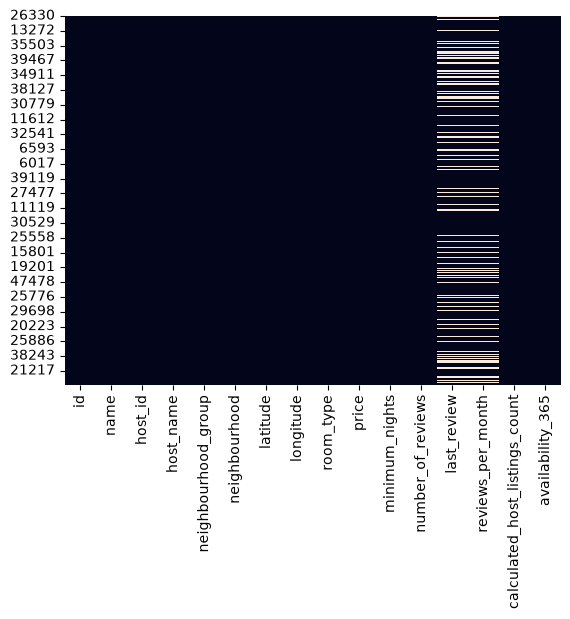

In [3]:
sns.heatmap(df.sample(500).isnull(), cbar=False)
plt.show()

In [4]:
len(df[df["number_of_reviews"] == 0])

10052

son los mismos que no tienen reseñas

In [5]:
len(df.dropna())

38821

si borro las filas se pierden como 10000, mejor relleno con 0

## item 4
copia con lo del item 2 y lo que hizo Lina en el 3

In [6]:
d = df.copy()
d["reviews_per_month"] = d["reviews_per_month"].fillna(0)
d["name"] = d["name"].fillna("sin nombre")
d = d[d["price"] <= 1000].copy()
d.shape

(48656, 16)

In [7]:
d.duplicated().sum()

np.int64(0)

In [8]:
d["neighbourhood_group"].unique()

<StringArray>
['Brooklyn', 'Manhattan', 'Queens', 'Staten Island', 'Bronx']
Length: 5, dtype: str

In [9]:
d[d["name"].str.isupper()]["name"].head(10)

2               THE VILLAGE OF HARLEM....NEW YORK !
28     SPACIOUS, LOVELY FURNISHED MANHATTAN BEDROOM
44                               BEST BET IN HARLEM
52                       * ORIGINAL BROOKLYN LOFT *
73                  HARLEM, NEW YORK WELCOMES YOU!!
74                            BLUE TRIM GUEST HOUSE
129                        ACCOMMODATIONS GALORE #1
138                                 FLAT MACDONOUGH
144                          FLAT MACDONOUGH GARDEN
175             BROOKLYN VICTORIAN STYLE SUITE.....
Name: name, dtype: str

In [10]:
pd.Series(["  COZY ROOM IN BROOKLYN ", "Sunny loft"]).str.strip().str.lower()

0    cozy room in brooklyn
1               sunny loft
dtype: str

In [11]:
d[d["price"] == 0][["name", "price"]]

,name,price
23161,"Huge Brooklyn Brownstone Living, Close to it all.",0
25433,★Hostel Style Room | Ideal Traveling Buddies★,0
25634,"MARTIAL LOFT 3: REDEMPTION (upstairs, 2nd room)",0
25753,"Sunny, Quiet Room in Greenpoint",0
25778,Modern apartment in the heart of Williamsburg,0
25794,Spacious comfortable master bedroom with nice ...,0
25795,Contemporary bedroom in brownstone with nice view,0
25796,Cozy yet spacious private brownstone bedroom,0
26259,the best you can find,0
26841,Coliving in Brooklyn! Modern design / Shared room,0


In [12]:
d[d["minimum_nights"] > 365][["name", "minimum_nights"]]

,name,minimum_nights
1305,800sqft apartment with huge terrace,370
2854,sin nombre,1000
5767,Prime W. Village location 1 bdrm,1250
7355,Beautiful Fully Furnished 1 bed/bth,500
8014,Wonderful Large 1 bedroom,500
10829,Brand New Luxury Apt Lease Takeover,480
11193,Zen Room in Crown Heights Brooklyn,500
13404,Historic Designer 2 Bed. Apartment,999
14285,Peaceful apartment close to F/G,500
15946,"Bright Luxury Studio, Central Loc.",366


## item 6
copia con todo hasta las variables nuevas de Lina

In [13]:
d = df.copy()
d["reviews_per_month"] = d["reviews_per_month"].fillna(0)
d["name"] = d["name"].fillna("sin nombre")
d = d[d["price"] <= 1000].copy()
d = d[(d["price"] > 0) & (d["minimum_nights"] <= 365)].copy()
d["tipo_precio"] = "medio"
d.loc[d["price"] <= 70, "tipo_precio"] = "barato"
d.loc[d["price"] > 150, "tipo_precio"] = "caro"
d["estancia_larga"] = d["minimum_nights"] >= 30
d.shape

(48631, 18)

In [14]:
len(d[(d["neighbourhood_group"] == "Manhattan") & (d["room_type"] == "Entire home/apt") & (d["price"] < 100)])

859

In [15]:
len(d[(d["neighbourhood_group"] == "Brooklyn") & (d["room_type"] == "Entire home/apt") & (d["price"] < 100)])

1807

en brooklyn hay muchos mas baratos que en manhattan

In [16]:
len(d[d["availability_365"] == 0])

17463

In [17]:
len(d[(d["neighbourhood_group"] == "Staten Island") & (d["tipo_precio"] == "caro")])

46

el de staten island da muy poquitos, no lo uso